# Analisis Klasifikasi Dry Bean: Decision Tree vs. Random Forest

**Mata kuliah:** Matematika Diskrit  
**Jenis pembelajaran:** Supervised Learning  
**Tugas:** Multiclass Classification  
**Dataset:** Dry Bean  
**Target:** `Class` (7 varietas kacang)  
**Algoritma:** Decision Tree dan Random Forest

## Tujuan
Notebook ini membangun dan membandingkan dua model klasifikasi dengan prosedur yang dapat direproduksi. Notebook memuat audit dataset, pembersihan, EDA, pembagian data, baseline, penggunaan hasil 5-fold cross-validation, training ulang menggunakan parameter terbaik, evaluasi testing, visualisasi, penyimpanan model, dan bukti prediksi.

**Prinsip metodologi:** kedua model memakai pembagian data yang sama; data testing tidak digunakan untuk tuning; Macro F1 menjadi metrik utama; semua random state ditetapkan agar hasil dapat direproduksi.


## Persiapan Google Colab (otomatis)

Jika notebook dijalankan di Google Colab dan folder proyek belum tersedia, jalankan sel berikut. Colab akan meminta satu kali unggahan file `Dry_Bean_Classification_Submission_FINAL.zip`, mengekstraknya, lalu mengatur direktori kerja secara otomatis. Tidak perlu mengetik kode konfigurasi atau mengubah path secara manual.

Jika folder proyek sudah tersedia atau notebook dijalankan dari folder proyek di Jupyter lokal, sel ini akan mendeteksi folder tersebut.

In [ ]:
from pathlib import Path
import os, zipfile

def _find_project_root(base: Path):
    candidates = [base, base / 'Dry_Bean_Classification_Project']
    for candidate in candidates:
        if (candidate / 'data' / 'Dry_Bean.csv').exists():
            return candidate.resolve()
    for candidate in base.iterdir():
        if candidate.is_dir() and (candidate / 'data' / 'Dry_Bean.csv').exists():
            return candidate.resolve()
    return None

_project_root = _find_project_root(Path.cwd())
if _project_root is None:
    try:
        from google.colab import files
    except ImportError as exc:
        raise FileNotFoundError('Folder proyek belum ditemukan. Di Jupyter lokal, ekstrak ZIP proyek dan buka notebook dari folder Dry_Bean_Classification_Project.') from exc
    print('Silakan pilih ZIP final: Dry_Bean_Classification_Submission_FINAL.zip')
    _uploaded_files = files.upload()
    _zip_names = [name for name in _uploaded_files if name.lower().endswith('.zip')]
    if not _zip_names:
        raise FileNotFoundError('File ZIP proyek tidak terdeteksi. Jalankan ulang sel ini dan pilih ZIP proyek.')
    _extract_base = Path('/content')
    with zipfile.ZipFile(_zip_names[0], 'r') as _archive:
        _archive.extractall(_extract_base)
    _project_root = _find_project_root(_extract_base)
    if _project_root is None:
        raise FileNotFoundError('ZIP berhasil diekstrak, tetapi struktur folder proyek tidak ditemukan.')

os.chdir(_project_root)
print('Direktori proyek aktif:', Path.cwd())
print('Dataset tersedia:', (Path.cwd() / 'data' / 'Dry_Bean.csv').exists())
print('Folder outputs:', (Path.cwd() / 'outputs').exists())
print('Folder models:', (Path.cwd() / 'models').exists())

## 1. Dasar matematis dan algoritmik

### 1.1 Supervised learning dan klasifikasi
Pada supervised learning, model mempelajari pemetaan dari fitur \(X\) menuju label \(y\) menggunakan pasangan data berlabel. Pada proyek ini, \(X\) berisi 16 karakteristik geometris, sedangkan \(y\) adalah satu dari tujuh varietas kacang.

### 1.2 Entropy
Entropy mengukur ketidakpastian distribusi kelas pada suatu himpunan data:

\[
H(S)=-\sum_{i=1}^{k}p_i\log_2(p_i)
\]

Nilai \(p_i\) adalah proporsi anggota kelas ke-\(i\). Entropy bernilai nol jika seluruh anggota himpunan berasal dari satu kelas.

### 1.3 Information Gain
Decision Tree memilih pemisahan fitur yang memberikan penurunan entropy terbesar:

\[
IG(S,A)=H(S)-\sum_{v\in Values(A)}\frac{|S_v|}{|S|}H(S_v)
\]

Kriteria `entropy` pada Decision Tree menggunakan prinsip ini. Kriteria `gini` merupakan alternatif impurity measure.

### 1.4 Random Forest dan majority voting
Random Forest membangun banyak pohon dari sampel bootstrap dan subset fitur yang dipilih secara acak. Untuk klasifikasi, prediksi akhir ditentukan melalui voting mayoritas:

\[
\hat{y}=\operatorname{mode}\{T_1(x),T_2(x),\ldots,T_B(x)\}
\]

### 1.5 Kaitan dengan Matematika Diskrit
- Himpunan: partisi data training dan testing serta himpunan kelas.
- Logika: aturan percabangan IF-THEN pada Decision Tree.
- Probabilitas: distribusi kelas, bootstrap sampling, dan estimasi performa.
- Kombinatorika: kombinasi pohon dan subset fitur pada Random Forest.
- Fungsi: pemetaan vektor fitur menjadi label kelas.


## 2. Import library dan konfigurasi

In [1]:
from pathlib import Path
import json, time, platform, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn import __version__ as sklearn_version
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.base import clone
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, matthews_corrcoef, cohen_kappa_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay)
import joblib
warnings.filterwarnings('ignore', category=FutureWarning)

RANDOM_STATE = 42
TEST_SIZE = 0.20
CV_FOLDS = 5
TARGET = 'Class'
PROJECT_DIR = Path.cwd()
DATA_PATH = PROJECT_DIR / 'data' / 'Dry_Bean.csv'
OUTPUT_DIR = PROJECT_DIR / 'outputs'
MODEL_DIR = PROJECT_DIR / 'models'
EVIDENCE_DIR = PROJECT_DIR / 'evidence'
for folder in [OUTPUT_DIR, MODEL_DIR, EVIDENCE_DIR]:
    folder.mkdir(parents=True, exist_ok=True)
if not DATA_PATH.exists():
    raise FileNotFoundError('File data/Dry_Bean.csv tidak ditemukan. Buka notebook dari folder proyek yang diekstrak.')
print('Python:', platform.python_version())
print('pandas:', pd.__version__, '| NumPy:', np.__version__, '| scikit-learn:', sklearn_version)
print('Dataset:', DATA_PATH.resolve())
print('Random state:', RANDOM_STATE)

Python: 3.13.5
pandas: 2.2.3 | NumPy: 2.3.5 | scikit-learn: 1.8.0
Dataset: /mnt/data/Dry_Bean_Classification_Project/data/Dry_Bean.csv
Random state: 42


## 3. Memuat dataset dan memahami struktur

In [2]:
df_raw = pd.read_csv(DATA_PATH)
assert TARGET in df_raw.columns
feature_cols = [c for c in df_raw.columns if c != TARGET]
print('Dimensi dataset:', df_raw.shape)
print('Jumlah fitur:', len(feature_cols))
print('Nama kolom:', df_raw.columns.tolist())
display(df_raw.head())
display(df_raw.dtypes.to_frame('dtype'))

Dimensi dataset: (13611, 17)
Jumlah fitur: 16
Nama kolom: ['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'AspectRation', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent', 'Solidity', 'roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor3', 'ShapeFactor4', 'Class']


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272751,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


,dtype
Area,int64
Perimeter,float64
MajorAxisLength,float64
MinorAxisLength,float64
AspectRation,float64
Eccentricity,float64
ConvexArea,int64
EquivDiameter,float64
Extent,float64
Solidity,float64


## 4. Audit kualitas data dan preprocessing

Audit mencakup missing values, tipe data, duplikasi eksak, dan konflik label. Ditemukan 68 baris duplikasi eksak, seluruhnya pada kelas HOROZ. Sumber dataset tidak menyediakan ID spesimen, sehingga tidak dapat dipastikan apakah baris identik merupakan duplikasi administrasi atau spesimen berbeda dengan pengukuran yang sama. Untuk eksperimen utama, satu salinan dari setiap baris identik dipertahankan agar rekaman identik tidak tersebar pada training dan testing. Keputusan ini dicatat sebagai keterbatasan dan perlu dijelaskan dalam laporan.


In [3]:
missing_by_column = df_raw.isna().sum()
duplicate_exact_count = int(df_raw.duplicated().sum())
duplicate_rows_all = df_raw.loc[df_raw.duplicated(keep=False)].copy()
duplicate_class_counts = duplicate_rows_all[TARGET].value_counts().to_dict()
duplicate_feature_groups = df_raw.groupby(feature_cols, dropna=False)[TARGET].nunique()
conflicting_feature_groups = int((duplicate_feature_groups > 1).sum())
non_numeric_features = [c for c in feature_cols if not pd.api.types.is_numeric_dtype(df_raw[c])]

quality_summary = {
    'raw_rows': int(len(df_raw)), 'raw_columns': int(df_raw.shape[1]),
    'feature_count': int(len(feature_cols)), 'target_column': TARGET,
    'missing_cells': int(df_raw.isna().sum().sum()),
    'exact_duplicate_rows_extra': duplicate_exact_count,
    'classes_containing_duplicate_rows': duplicate_class_counts,
    'conflicting_feature_label_groups': conflicting_feature_groups,
    'non_numeric_feature_columns': non_numeric_features,
    'target_classes': sorted(df_raw[TARGET].dropna().unique().tolist()),
    'target_class_count': int(df_raw[TARGET].nunique())
}
display(pd.Series(quality_summary, name='value').to_frame())
display(missing_by_column.to_frame('missing_count'))
if conflicting_feature_groups:
    raise ValueError('Ada kombinasi fitur identik dengan label berbeda; investigasi diperlukan.')
if non_numeric_features:
    raise TypeError(f'Fitur non-numerik ditemukan: {non_numeric_features}')
if df_raw[TARGET].isna().any() or df_raw[feature_cols].isna().any().any():
    raise ValueError('Missing value ditemukan; strategi imputasi perlu ditentukan sebelum training.')

df_clean = df_raw.loc[~df_raw.duplicated(keep='first')].copy().reset_index()
df_clean = df_clean.rename(columns={'index':'source_row_index'})
quality_summary['clean_rows'] = int(len(df_clean))
quality_summary['removed_exact_duplicates'] = int(len(df_raw)-len(df_clean))
quality_summary['clean_missing_cells'] = int(df_clean.isna().sum().sum())
df_clean.to_csv(OUTPUT_DIR/'cleaned_dry_bean.csv', index=False)
with open(EVIDENCE_DIR/'data_quality_report.json','w',encoding='utf-8') as f:
    json.dump(quality_summary, f, indent=2, ensure_ascii=False)
print(f"Rows: {len(df_raw):,} -> {len(df_clean):,}; exact duplicate rows removed: {len(df_raw)-len(df_clean):,}")
print('Distribusi kelas pada baris duplikat:', duplicate_class_counts)

,value
raw_rows,13611
raw_columns,17
feature_count,16
target_column,Class
missing_cells,0
exact_duplicate_rows_extra,68
classes_containing_duplicate_rows,{'HOROZ': 136}
conflicting_feature_label_groups,0
non_numeric_feature_columns,[]
target_classes,"[BARBUNYA, BOMBAY, CALI, DERMASON, HOROZ, SEKE..."


,missing_count
Area,0
Perimeter,0
MajorAxisLength,0
MinorAxisLength,0
AspectRation,0
Eccentricity,0
ConvexArea,0
EquivDiameter,0
Extent,0
Solidity,0


Rows: 13,611 -> 13,543; exact duplicate rows removed: 68
Distribusi kelas pada baris duplikat: {'HOROZ': 136}


## 5. Distribusi kelas dan statistik deskriptif

,count,percentage
Class,,
BARBUNYA,1322,9.76
BOMBAY,522,3.85
CALI,1630,12.04
DERMASON,3546,26.18
HOROZ,1860,13.73
SEKER,2027,14.97
SIRA,2636,19.46


,count,mean,std,min,25%,50%,75%,max
Area,13543.0,53048.460385,29392.438324,20420.000000,36282.500000,44580.000000,61382.000000,254616.000000
Perimeter,13543.0,854.993406,214.722684,524.736000,703.230000,793.896000,977.146500,1985.370000
MajorAxisLength,13543.0,319.895602,85.809260,183.601165,253.086806,296.404589,376.312489,738.860154
MinorAxisLength,13543.0,202.365321,45.051632,122.512653,175.886357,192.491117,217.245403,460.198497
AspectRation,13543.0,1.581075,0.245245,1.024868,1.430662,1.549860,1.703916,2.430306
Eccentricity,13543.0,0.750315,0.091858,0.218951,0.715144,0.763997,0.809671,0.911423
ConvexArea,13543.0,53767.986709,29844.248525,20684.000000,36673.000000,45122.000000,62360.000000,263261.000000
EquivDiameter,13543.0,253.034094,59.307709,161.243764,214.933277,238.245711,279.560351,569.374358
Extent,13543.0,0.749829,0.048939,0.555315,0.718735,0.759903,0.786849,0.866195
Solidity,13543.0,0.987152,0.004650,0.919246,0.985678,0.988288,0.990019,0.994677


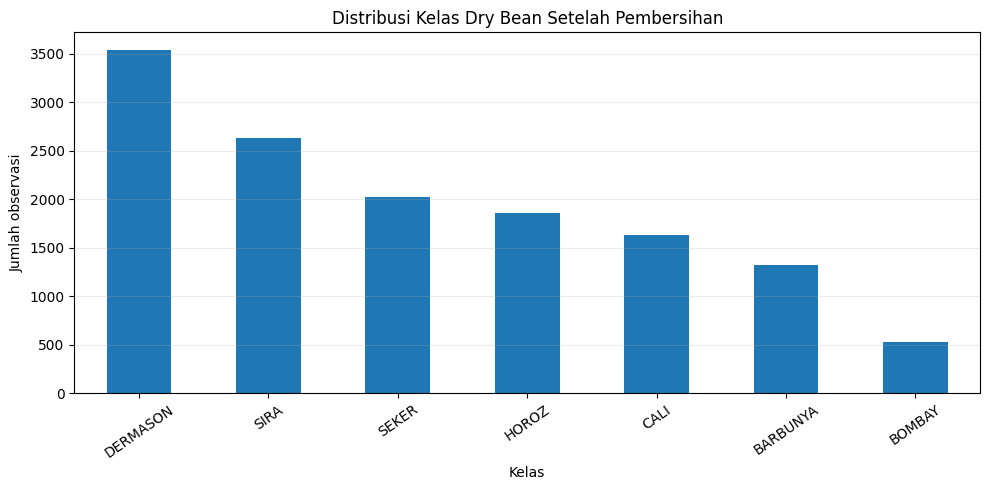

In [4]:
class_counts = df_clean[TARGET].value_counts().sort_index()
class_distribution = pd.DataFrame({'count':class_counts,
    'percentage':(class_counts/class_counts.sum()*100).round(2)})
display(class_distribution)
display(df_clean[feature_cols].describe().T)
df_clean[feature_cols].describe().T.to_csv(OUTPUT_DIR/'descriptive_statistics.csv')
class_distribution.to_csv(OUTPUT_DIR/'class_distribution.csv')
fig, ax = plt.subplots(figsize=(10,5))
class_counts.sort_values(ascending=False).plot(kind='bar', ax=ax)
ax.set_title('Distribusi Kelas Dry Bean Setelah Pembersihan')
ax.set_xlabel('Kelas'); ax.set_ylabel('Jumlah observasi'); ax.tick_params(axis='x', rotation=35)
ax.grid(axis='y', alpha=.25); fig.tight_layout()
fig.savefig(OUTPUT_DIR/'class_distribution.png', dpi=180, bbox_inches='tight')
plt.show()

## 6. Exploratory Data Analysis (EDA)

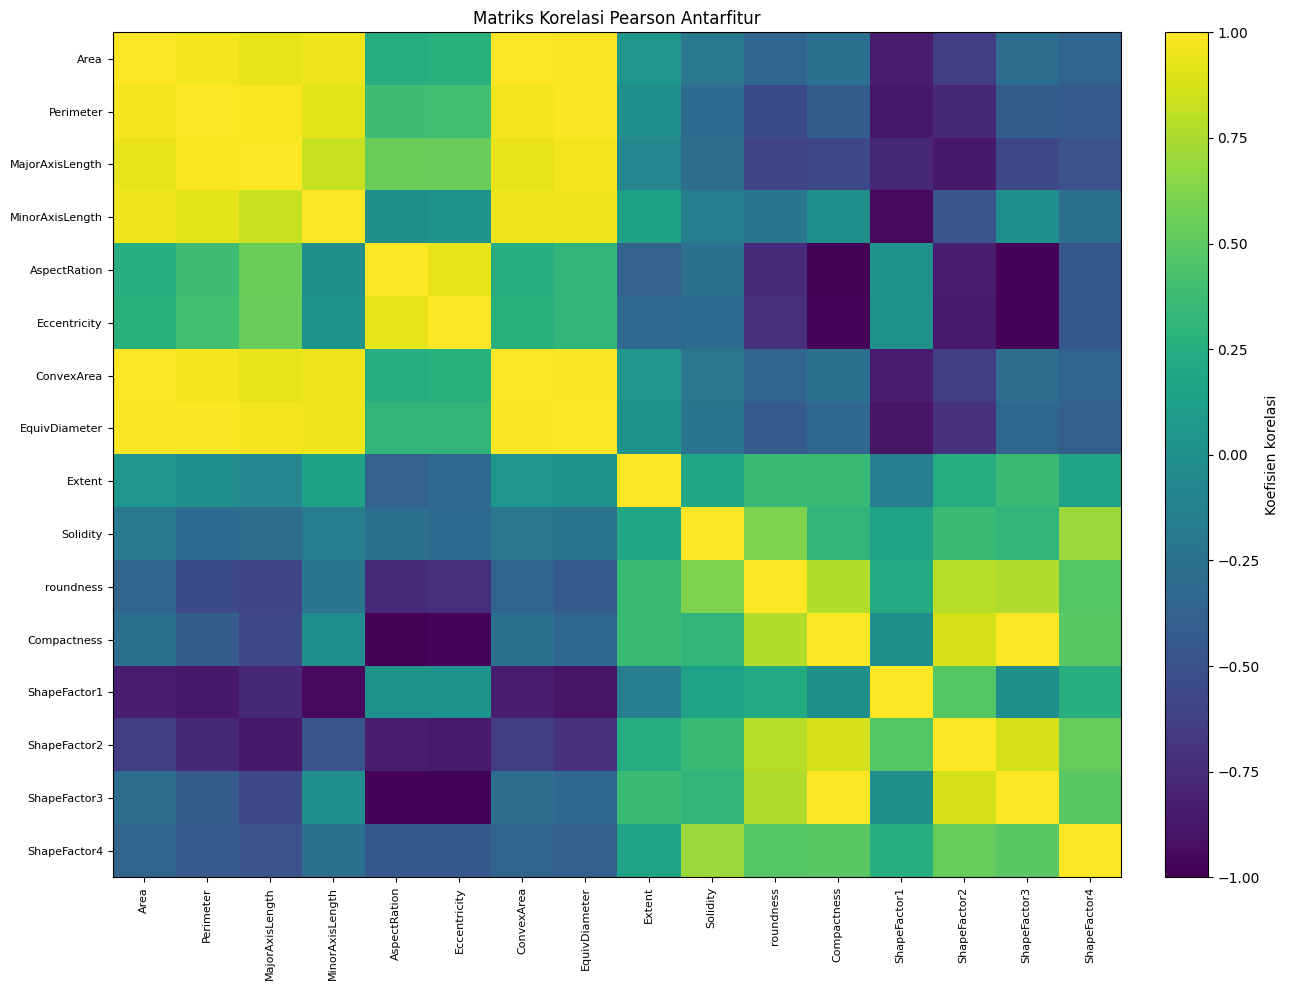

,feature_1,feature_2,correlation
5,Area,ConvexArea,0.999940
112,Compactness,ShapeFactor3,0.998684
20,Perimeter,EquivDiameter,0.991453
60,AspectRation,Compactness,-0.987644
75,ConvexArea,EquivDiameter,0.985255
6,Area,EquivDiameter,0.984998
73,Eccentricity,ShapeFactor3,-0.981058
63,AspectRation,ShapeFactor3,-0.978528
15,Perimeter,MajorAxisLength,0.977561
70,Eccentricity,Compactness,-0.970308


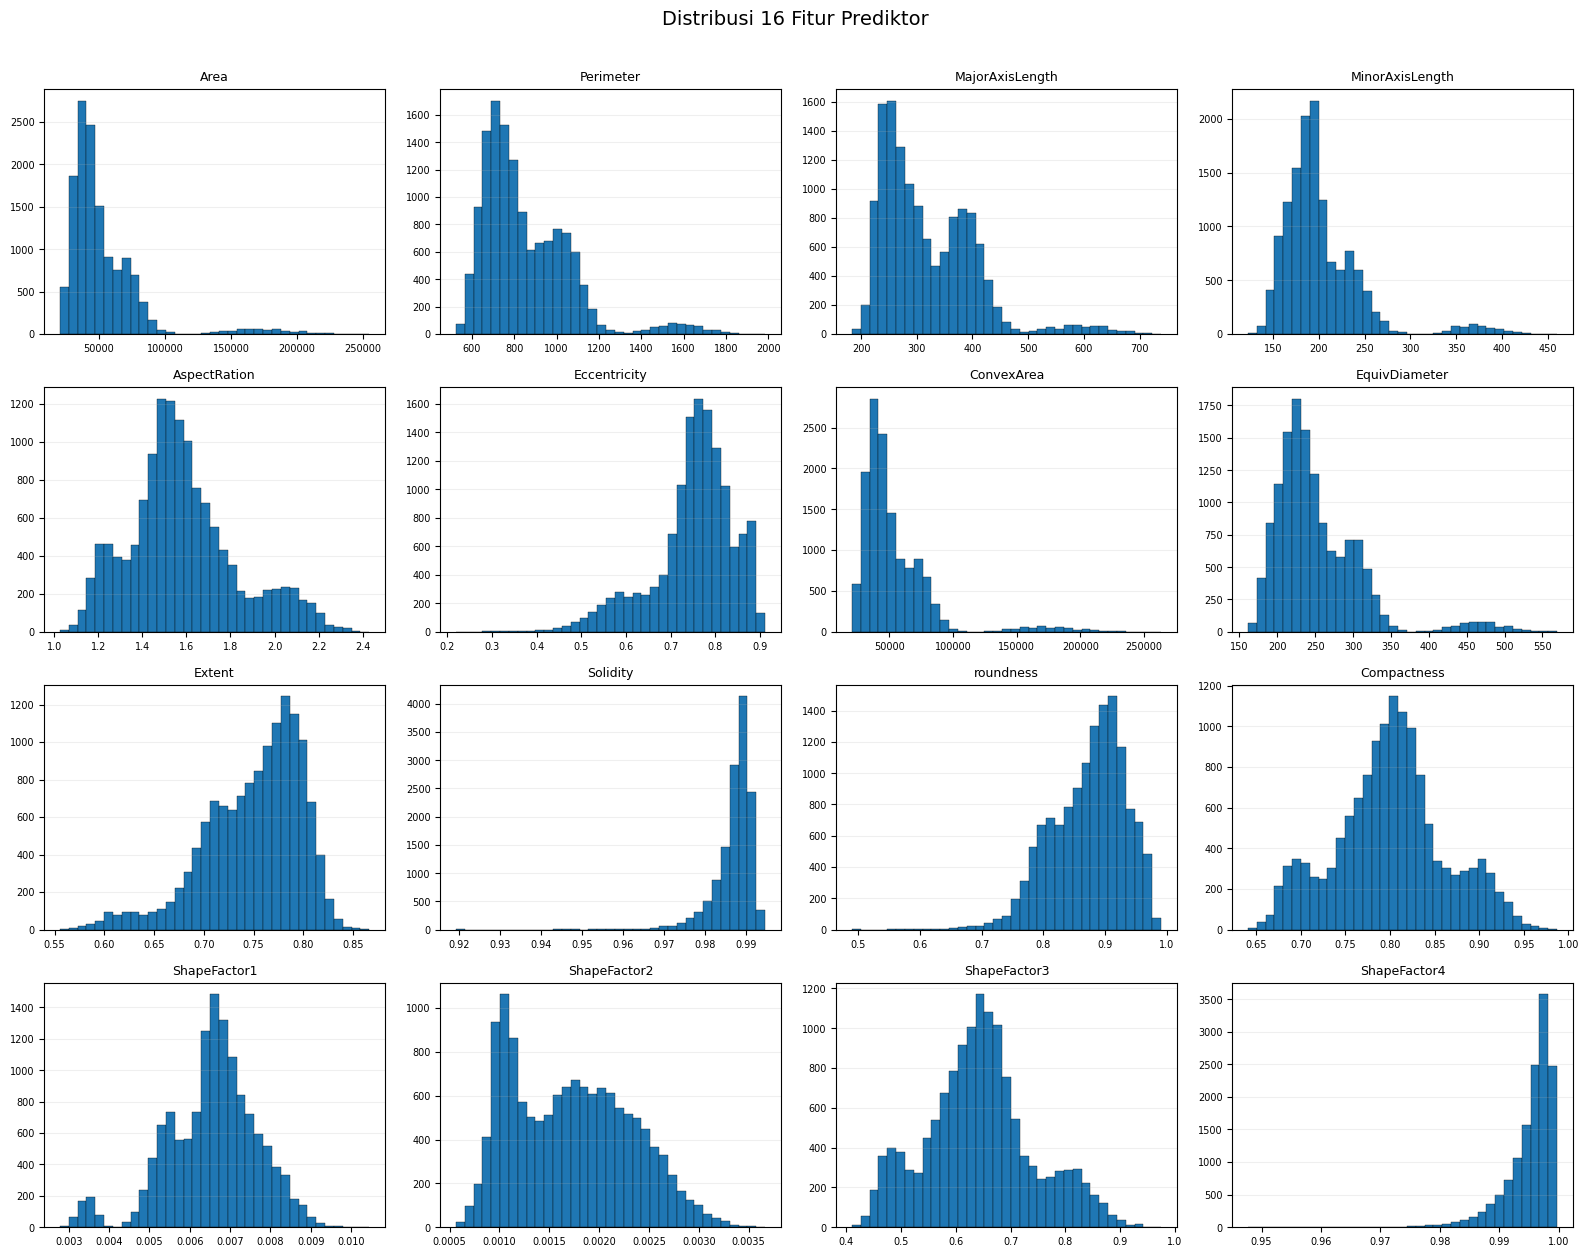

In [5]:
corr = df_clean[feature_cols].corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(13,10))
im = ax.imshow(corr, aspect='auto', interpolation='nearest', vmin=-1, vmax=1, cmap='viridis')
ax.set_xticks(range(len(feature_cols))); ax.set_yticks(range(len(feature_cols)))
ax.set_xticklabels(feature_cols, rotation=90, fontsize=8); ax.set_yticklabels(feature_cols, fontsize=8)
ax.set_title('Matriks Korelasi Pearson Antarfitur')
fig.colorbar(im, ax=ax, fraction=.046, pad=.04, label='Koefisien korelasi')
fig.tight_layout(); fig.savefig(OUTPUT_DIR/'correlation_heatmap.png', dpi=180, bbox_inches='tight'); plt.show()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
high_corr_pairs = upper.stack().reset_index()
high_corr_pairs.columns = ['feature_1','feature_2','correlation']
high_corr_pairs = high_corr_pairs.loc[high_corr_pairs.correlation.abs()>=.90].sort_values('correlation', key=lambda s:s.abs(), ascending=False)
display(high_corr_pairs)
high_corr_pairs.to_csv(OUTPUT_DIR/'high_correlation_pairs.csv', index=False)

n_cols=4; n_rows=int(np.ceil(len(feature_cols)/n_cols))
fig, axes=plt.subplots(n_rows,n_cols,figsize=(16,n_rows*3.1)); axes=np.array(axes).reshape(-1)
for i,col in enumerate(feature_cols):
    axes[i].hist(df_clean[col],bins=35,edgecolor='black',linewidth=.25)
    axes[i].set_title(col,fontsize=9); axes[i].tick_params(axis='both',labelsize=7); axes[i].grid(axis='y',alpha=.2)
for j in range(len(feature_cols),len(axes)): axes[j].axis('off')
fig.suptitle('Distribusi 16 Fitur Prediktor',fontsize=14,y=1.01); fig.tight_layout()
fig.savefig(OUTPUT_DIR/'feature_distributions.png',dpi=180,bbox_inches='tight'); plt.show()

## 7. Pembagian training dan testing

Pembagian menggunakan stratified sampling 80:20. Stratifikasi menjaga proporsi relatif tujuh kelas pada kedua subset. Kedua algoritma menerima data yang sama agar perbandingan adil.


In [6]:
X = df_clean[feature_cols].copy(); y = df_clean[TARGET].copy()
train_idx, test_idx = train_test_split(np.arange(len(df_clean)), test_size=TEST_SIZE,
    random_state=RANDOM_STATE, stratify=y)
X_train, X_test = X.iloc[train_idx].copy(), X.iloc[test_idx].copy()
y_train, y_test = y.iloc[train_idx].copy(), y.iloc[test_idx].copy()
train_evidence, test_evidence = df_clean.iloc[train_idx].copy(), df_clean.iloc[test_idx].copy()
train_evidence.to_csv(EVIDENCE_DIR/'training_set.csv',index=False)
test_evidence.to_csv(EVIDENCE_DIR/'testing_set.csv',index=False)
split_summary = pd.DataFrame({'subset':['Training','Testing','Total'],
    'observations':[len(train_idx),len(test_idx),len(df_clean)],
    'percentage':[len(train_idx)/len(df_clean)*100,len(test_idx)/len(df_clean)*100,100]})
display(split_summary)
split_class = pd.DataFrame({'training_count':y_train.value_counts().sort_index(),
    'testing_count':y_test.value_counts().sort_index()})
display(split_class)
assert set(train_idx).isdisjoint(set(test_idx))
assert set(y_train.unique()) == set(y_test.unique())
split_summary.to_csv(EVIDENCE_DIR/'split_summary.csv',index=False)
split_class.to_csv(EVIDENCE_DIR/'split_class_distribution.csv')

,subset,observations,percentage
0,Training,10834,79.997046
1,Testing,2709,20.002954
2,Total,13543,100.000000


,training_count,testing_count
Class,,
BARBUNYA,1057,265
BOMBAY,418,104
CALI,1304,326
DERMASON,2837,709
HOROZ,1488,372
SEKER,1621,406
SIRA,2109,527


## 8. Baseline training

In [7]:
def calculate_metrics(y_true,y_pred):
    return {'accuracy':accuracy_score(y_true,y_pred),
        'balanced_accuracy':balanced_accuracy_score(y_true,y_pred),
        'precision_macro':precision_score(y_true,y_pred,average='macro',zero_division=0),
        'recall_macro':recall_score(y_true,y_pred,average='macro',zero_division=0),
        'f1_macro':f1_score(y_true,y_pred,average='macro',zero_division=0),
        'f1_weighted':f1_score(y_true,y_pred,average='weighted',zero_division=0),
        'matthews_corrcoef':matthews_corrcoef(y_true,y_pred),
        'cohen_kappa':cohen_kappa_score(y_true,y_pred)}

baseline_models = {
    'Decision Tree':DecisionTreeClassifier(random_state=RANDOM_STATE),
    'Random Forest':RandomForestClassifier(random_state=RANDOM_STATE,n_jobs=1)}
baseline_fitted={}; baseline_rows=[]; baseline_predictions={}
for name,model in baseline_models.items():
    t0=time.perf_counter(); model.fit(X_train,y_train); elapsed=time.perf_counter()-t0
    pred=model.predict(X_test); baseline_fitted[name]=model; baseline_predictions[name]=pred
    row={'model':name,'fit_seconds':elapsed}; row.update(calculate_metrics(y_test,pred)); baseline_rows.append(row)
baseline_metrics=pd.DataFrame(baseline_rows).set_index('model')
display(baseline_metrics.round(4)); baseline_metrics.to_csv(OUTPUT_DIR/'baseline_metrics.csv')

,fit_seconds,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,matthews_corrcoef,cohen_kappa
model,,,,,,,,,
Decision Tree,0.2145,0.8955,0.9104,0.9094,0.9104,0.9098,0.8953,0.8737,0.8737
Random Forest,3.2287,0.9169,0.9281,0.9302,0.9281,0.9290,0.9169,0.8995,0.8995


## 9. Hyperparameter tuning dan cross-validation

Hasil pencarian kandidat 5-fold Stratified Cross-Validation yang sudah dijalankan disimpan di folder `evidence/`. Secara default notebook membaca hasil pencarian tersebut, kemudian melatih ulang model dari awal menggunakan parameter terbaik. Dengan demikian, bukti pencarian parameter tetap tersedia dan notebook dapat dijalankan lebih cepat.

Jika ingin mengulang seluruh pencarian dari awal, ubah `RUN_FULL_TUNING` menjadi `True`. Proses ini akan menguji 8 kandidat Decision Tree dan 7 kandidat Random Forest menggunakan 5-fold CV dan dapat memerlukan waktu lebih lama.


In [8]:
RUN_FULL_TUNING = False  # Ubah ke True untuk mengulang semua kandidat 5-fold CV
cv_strategy=StratifiedKFold(n_splits=CV_FOLDS,shuffle=True,random_state=RANDOM_STATE)

baseline_cv_path = OUTPUT_DIR/'baseline_cv_summary.csv'
if baseline_cv_path.exists():
    print('Baseline 5-fold CV reference scores:')
    display(pd.read_csv(baseline_cv_path))

candidate_paths = {
    'Decision Tree': EVIDENCE_DIR/'cv_results_decision_tree.csv',
    'Random Forest': EVIDENCE_DIR/'cv_results_random_forest.csv'
}
base_estimators = {
    'Decision Tree': DecisionTreeClassifier(random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(random_state=RANDOM_STATE,n_jobs=1)
}
tuning_rows=[]; tuning_tables={}; best_params_by_model={}; best_cv_by_model={}

for model_name, path in candidate_paths.items():
    if not path.exists():
        raise FileNotFoundError(f'Bukti kandidat tuning tidak ditemukan: {path}')
    candidate_df = pd.read_csv(path)
    candidate_df['params_dict'] = candidate_df['params'].apply(json.loads)
    if RUN_FULL_TUNING:
        rerun_rows=[]
        for candidate_id, params in enumerate(candidate_df['params_dict'], start=1):
            estimator=clone(base_estimators[model_name]).set_params(**params)
            t0=time.perf_counter()
            scores=cross_val_score(estimator,X_train,y_train,cv=cv_strategy,scoring='f1_macro',n_jobs=1)
            rerun_rows.append({'candidate_id':candidate_id,'params':json.dumps(params,default=str),
                'mean_test_score':float(np.mean(scores)),'std_test_score':float(np.std(scores,ddof=1)),
                'fold_scores':json.dumps([float(v) for v in scores]),'fit_evaluation_seconds':time.perf_counter()-t0})
        candidate_df=pd.DataFrame(rerun_rows).sort_values('mean_test_score',ascending=False).reset_index(drop=True)
        candidate_df['rank_test_score']=np.arange(1,len(candidate_df)+1)
        candidate_df.to_csv(path,index=False)
    else:
        candidate_df=candidate_df.sort_values('mean_test_score',ascending=False).reset_index(drop=True)
        if 'rank_test_score' not in candidate_df.columns:
            candidate_df['rank_test_score']=np.arange(1,len(candidate_df)+1)
    best_row=candidate_df.iloc[0]
    best_params=json.loads(best_row['params'])
    best_params_by_model[model_name]=best_params
    best_cv_by_model[model_name]=float(best_row['mean_test_score'])
    tuning_tables[model_name]=candidate_df.drop(columns=['params_dict'],errors='ignore')
    tuning_rows.append({'model':model_name,'candidate_count':len(candidate_df),'cv_folds':CV_FOLDS,
        'best_cv_macro_f1':float(best_row['mean_test_score']),'best_params':json.dumps(best_params,default=str)})
    print(f"{model_name}: {len(candidate_df)} kandidat; best CV Macro F1={best_row['mean_test_score']:.5f}")
    display(candidate_df.drop(columns=['params_dict'],errors='ignore'))

tuning_summary=pd.DataFrame(tuning_rows)
display(tuning_summary)
tuning_summary.to_csv(OUTPUT_DIR/'tuning_summary.csv',index=False)

Baseline 5-fold CV reference scores:


,model,baseline_cv_macro_f1,fold_scores
0,Decision Tree,0.910675,"[0.9127648826616795, 0.9035887294194538, 0.911..."
1,Random Forest,0.934137,"[0.9380599852536304, 0.9272762052660923, 0.929..."


Decision Tree: 8 kandidat; best CV Macro F1=0.92237


,candidate_id,params,mean_test_score,std_test_score,fold_scores,fit_evaluation_seconds,rank_test_score
0,8,"{""criterion"": ""entropy"", ""max_depth"": 25, ""min...",0.922370,0.006151,"[0.9204945232763481, 0.9262766384471443, 0.913...",0.895979,1
1,5,"{""criterion"": ""gini"", ""max_depth"": 25, ""min_sa...",0.920831,0.005126,"[0.9257636322732781, 0.9235201042516569, 0.916...",0.804396,2
2,2,"{""criterion"": ""entropy"", ""max_depth"": null, ""m...",0.913277,0.006426,"[0.9163958255381905, 0.91213659962501, 0.90405...",0.975906,3
3,3,"{""criterion"": ""gini"", ""max_depth"": 16, ""min_sa...",0.913014,0.004551,"[0.9157390620886188, 0.9064500562082233, 0.911...",0.869993,4
4,4,"{""criterion"": ""entropy"", ""max_depth"": 20, ""min...",0.912854,0.007944,"[0.9166120178438737, 0.9076592546983555, 0.901...",0.940115,5
5,1,"{""criterion"": ""gini"", ""max_depth"": null, ""min_...",0.910675,0.005163,"[0.9127648826616795, 0.9035887294194538, 0.911...",0.868591,6
6,7,"{""criterion"": ""gini"", ""max_depth"": 20, ""min_sa...",0.908020,0.008545,"[0.9018020496360852, 0.9027063453427088, 0.902...",0.679128,7
7,6,"{""criterion"": ""entropy"", ""max_depth"": null, ""m...",0.903461,0.007710,"[0.9143847321049501, 0.9000166645997172, 0.897...",0.310754,8


Random Forest: 7 kandidat; best CV Macro F1=0.93522


,candidate_id,params,mean_test_score,std_test_score,fold_scores,fit_evaluation_seconds,rank_test_score
0,6,"{""n_estimators"": 150, ""criterion"": ""entropy"", ...",0.935224,0.005882,"[0.9410404750073099, 0.9308280009835332, 0.929...",22.672265,1
1,5,"{""n_estimators"": 100, ""criterion"": ""gini"", ""ma...",0.935014,0.006052,"[0.9384207993347687, 0.9299731055056133, 0.928...",12.353453,2
2,3,"{""n_estimators"": 100, ""criterion"": ""entropy"", ...",0.934974,0.005071,"[0.9391241803324543, 0.9317289364883908, 0.929...",15.658078,3
3,2,"{""n_estimators"": 100, ""criterion"": ""gini"", ""ma...",0.934885,0.005890,"[0.9381165397084992, 0.9299731055056133, 0.928...",13.334238,4
4,7,"{""n_estimators"": 200, ""criterion"": ""gini"", ""ma...",0.934834,0.006905,"[0.9403288643080583, 0.9293390996297722, 0.927...",25.842528,5
5,1,"{""n_estimators"": 100, ""criterion"": ""gini"", ""ma...",0.934137,0.006084,"[0.9380599852536304, 0.9272762052660923, 0.929...",13.161705,6
6,4,"{""n_estimators"": 100, ""criterion"": ""gini"", ""ma...",0.934055,0.006195,"[0.9384847213261281, 0.9266725547000826, 0.929...",13.164585,7


,model,candidate_count,cv_folds,best_cv_macro_f1,best_params
0,Decision Tree,8,5,0.922370,"{""criterion"": ""entropy"", ""max_depth"": 25, ""min..."
1,Random Forest,7,5,0.935224,"{""n_estimators"": 150, ""criterion"": ""entropy"", ..."


## 10. Training ulang menggunakan parameter terbaik

In [9]:
tuned_models={}; tuned_fit_times={}
for name,params in best_params_by_model.items():
    model=clone(base_estimators[name]).set_params(**params)
    t0=time.perf_counter(); model.fit(X_train,y_train); tuned_fit_times[name]=time.perf_counter()-t0
    tuned_models[name]=model
    print(f'{name}: fitted on {len(X_train):,} training rows in {tuned_fit_times[name]:.2f} seconds')


Decision Tree: fitted on 10,834 training rows in 0.21 seconds


Random Forest: fitted on 10,834 training rows in 5.59 seconds


## 11. Evaluasi final pada testing set

In [10]:
final_predictions={}; final_rows=[]
for name,model in tuned_models.items():
    pred=model.predict(X_test); final_predictions[name]=pred
    row={'model':name}; row.update(calculate_metrics(y_test,pred))
    row['train_accuracy']=accuracy_score(y_train,model.predict(X_train))
    row['cv_best_macro_f1']=best_cv_by_model[name]
    row['fit_seconds']=tuned_fit_times[name]
    final_rows.append(row)
    report=classification_report(y_test,pred,output_dict=True,zero_division=0)
    pd.DataFrame(report).T.to_csv(OUTPUT_DIR/f"classification_report_{name.lower().replace(' ','_')}.csv")
final_metrics=pd.DataFrame(final_rows).set_index('model')
display(final_metrics.round(4)); final_metrics.to_csv(OUTPUT_DIR/'final_test_metrics.csv')
comparison=[]
for name in baseline_metrics.index:
    for stage,source in [('Baseline',baseline_metrics.loc[name]),('Tuned',final_metrics.loc[name])]:
        comparison.append({'model':name,'stage':stage,**{m:source[m] for m in ['accuracy','balanced_accuracy','precision_macro','recall_macro','f1_macro','f1_weighted']}})
comparison_df=pd.DataFrame(comparison)
display(comparison_df.round(4)); comparison_df.to_csv(OUTPUT_DIR/'model_comparison.csv',index=False)

,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,matthews_corrcoef,cohen_kappa,train_accuracy,cv_best_macro_f1,fit_seconds
model,,,,,,,,,,,
Decision Tree,0.8948,0.9081,0.9086,0.9081,0.9081,0.8946,0.8728,0.8727,0.9673,0.9224,0.2108
Random Forest,0.9177,0.9284,0.9309,0.9284,0.9296,0.9177,0.9004,0.9004,0.9910,0.9352,5.5880


,model,stage,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,f1_weighted
0,Decision Tree,Baseline,0.8955,0.9104,0.9094,0.9104,0.9098,0.8953
1,Decision Tree,Tuned,0.8948,0.9081,0.9086,0.9081,0.9081,0.8946
2,Random Forest,Baseline,0.9169,0.9281,0.9302,0.9281,0.9290,0.9169
3,Random Forest,Tuned,0.9177,0.9284,0.9309,0.9284,0.9296,0.9177


## 12. Confusion matrix dan analisis kesalahan

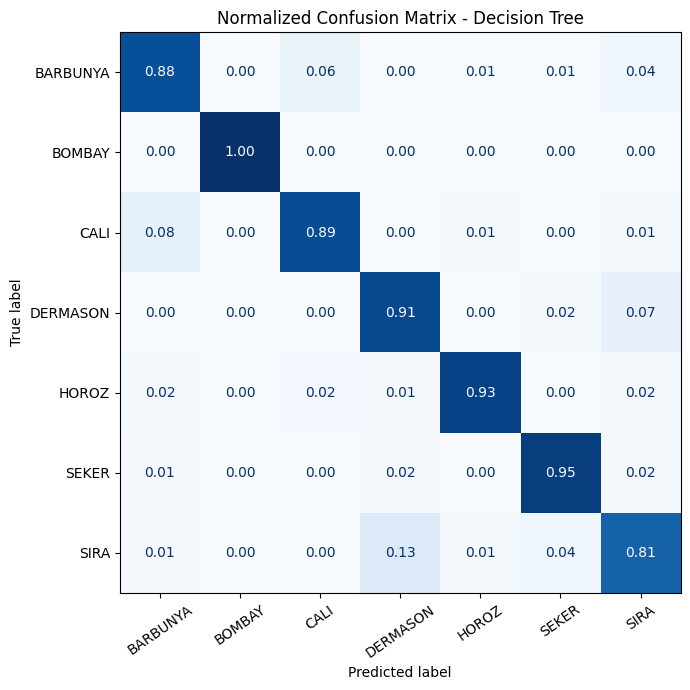

Decision Tree : 285 errors from 2709 testing rows


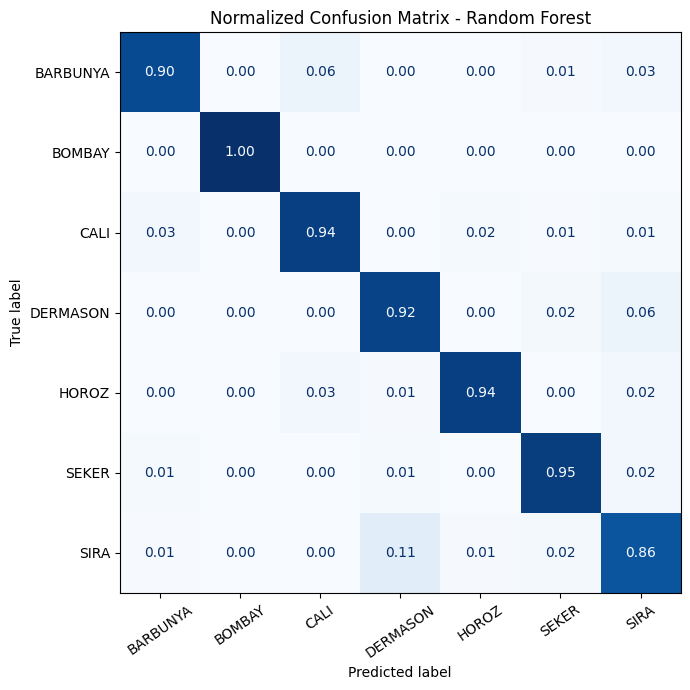

Random Forest : 223 errors from 2709 testing rows


In [11]:
class_labels=sorted(y.unique())
for name,pred in final_predictions.items():
    safe=name.lower().replace(' ','_')
    cm=confusion_matrix(y_test,pred,labels=class_labels)
    cmn=confusion_matrix(y_test,pred,labels=class_labels,normalize='true')
    pd.DataFrame(cm,index=class_labels,columns=class_labels).to_csv(EVIDENCE_DIR/f'confusion_matrix_counts_{safe}.csv')
    pd.DataFrame(cmn,index=class_labels,columns=class_labels).to_csv(EVIDENCE_DIR/f'confusion_matrix_normalized_{safe}.csv')
    fig,ax=plt.subplots(figsize=(8,7))
    ConfusionMatrixDisplay(confusion_matrix=cmn,display_labels=class_labels).plot(ax=ax,cmap='Blues',values_format='.2f',colorbar=False)
    ax.set_title(f'Normalized Confusion Matrix - {name}'); ax.tick_params(axis='x',rotation=35)
    fig.tight_layout(); fig.savefig(OUTPUT_DIR/f'confusion_matrix_{safe}.png',dpi=180,bbox_inches='tight'); plt.show()
    pred_df=test_evidence[['source_row_index']].copy(); pred_df['actual_class']=y_test.values
    pred_df['predicted_class']=pred; pred_df['correct']=pred_df.actual_class==pred
    pred_df.to_csv(EVIDENCE_DIR/f'predictions_{safe}.csv',index=False)
    pred_df.loc[~pred_df.correct].to_csv(EVIDENCE_DIR/f'misclassified_rows_{safe}.csv',index=False)
    print(name,':',int((~pred_df.correct).sum()),'errors from',len(pred_df),'testing rows')

## 13. Feature importance dan interpretasi

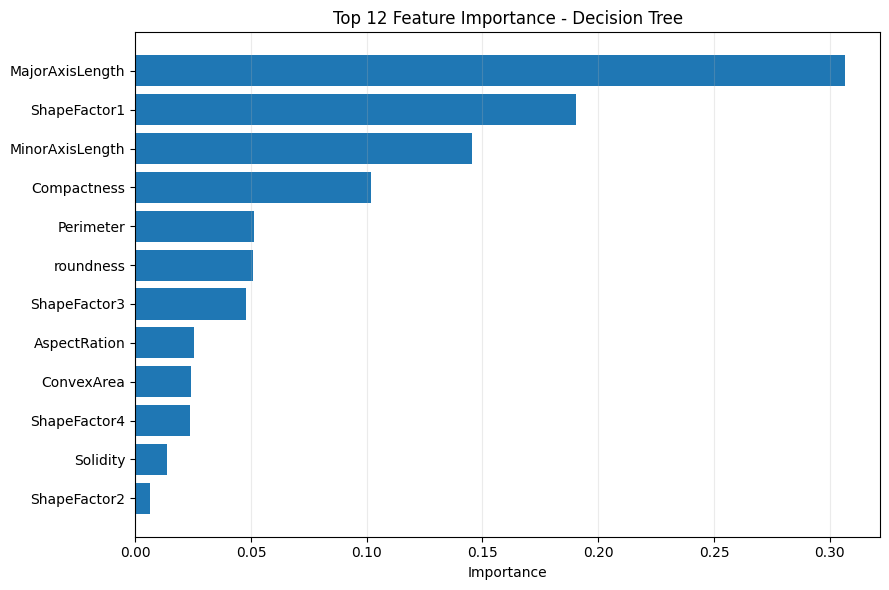

,feature,importance
2,MajorAxisLength,0.306375
12,ShapeFactor1,0.190600
3,MinorAxisLength,0.145255
11,Compactness,0.101968
1,Perimeter,0.051418
10,roundness,0.051021
14,ShapeFactor3,0.048006
4,AspectRation,0.025450
6,ConvexArea,0.024067
15,ShapeFactor4,0.023621


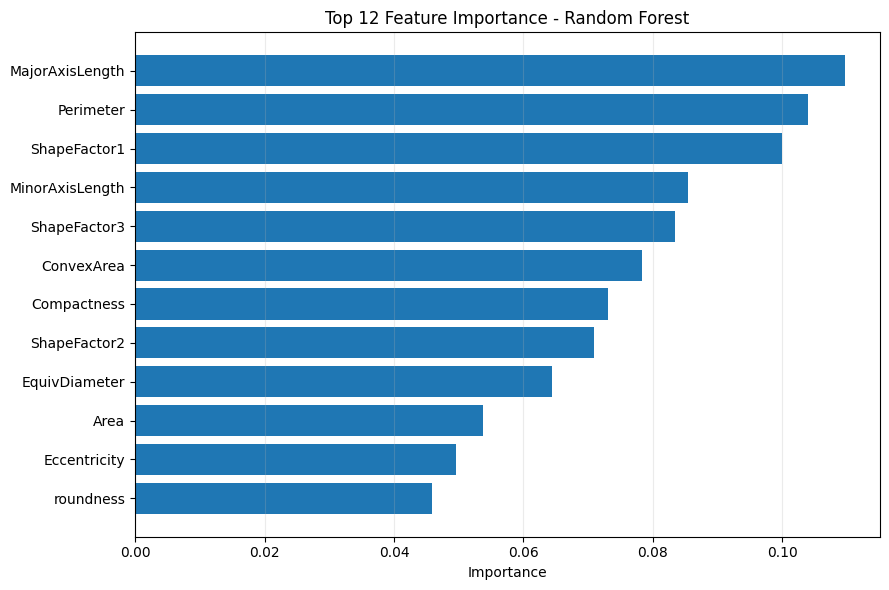

,feature,importance
2,MajorAxisLength,0.109615
1,Perimeter,0.104040
12,ShapeFactor1,0.099985
3,MinorAxisLength,0.085397
14,ShapeFactor3,0.083487
6,ConvexArea,0.078370
11,Compactness,0.073035
13,ShapeFactor2,0.070964
7,EquivDiameter,0.064393
0,Area,0.053821


In [12]:
feature_importance_tables={}
for name,model in tuned_models.items():
    safe=name.lower().replace(' ','_')
    imp=pd.DataFrame({'feature':feature_cols,'importance':model.feature_importances_}).sort_values('importance',ascending=False)
    feature_importance_tables[name]=imp; imp.to_csv(OUTPUT_DIR/f'feature_importance_{safe}.csv',index=False)
    top=imp.head(12).sort_values('importance')
    fig,ax=plt.subplots(figsize=(9,6)); ax.barh(top.feature,top.importance)
    ax.set_title(f'Top 12 Feature Importance - {name}'); ax.set_xlabel('Importance'); ax.grid(axis='x',alpha=.25)
    fig.tight_layout(); fig.savefig(OUTPUT_DIR/f'feature_importance_{safe}.png',dpi=180,bbox_inches='tight'); plt.show()
    display(imp.head(12))

## 14. Visualisasi Decision Tree dan perbandingan model

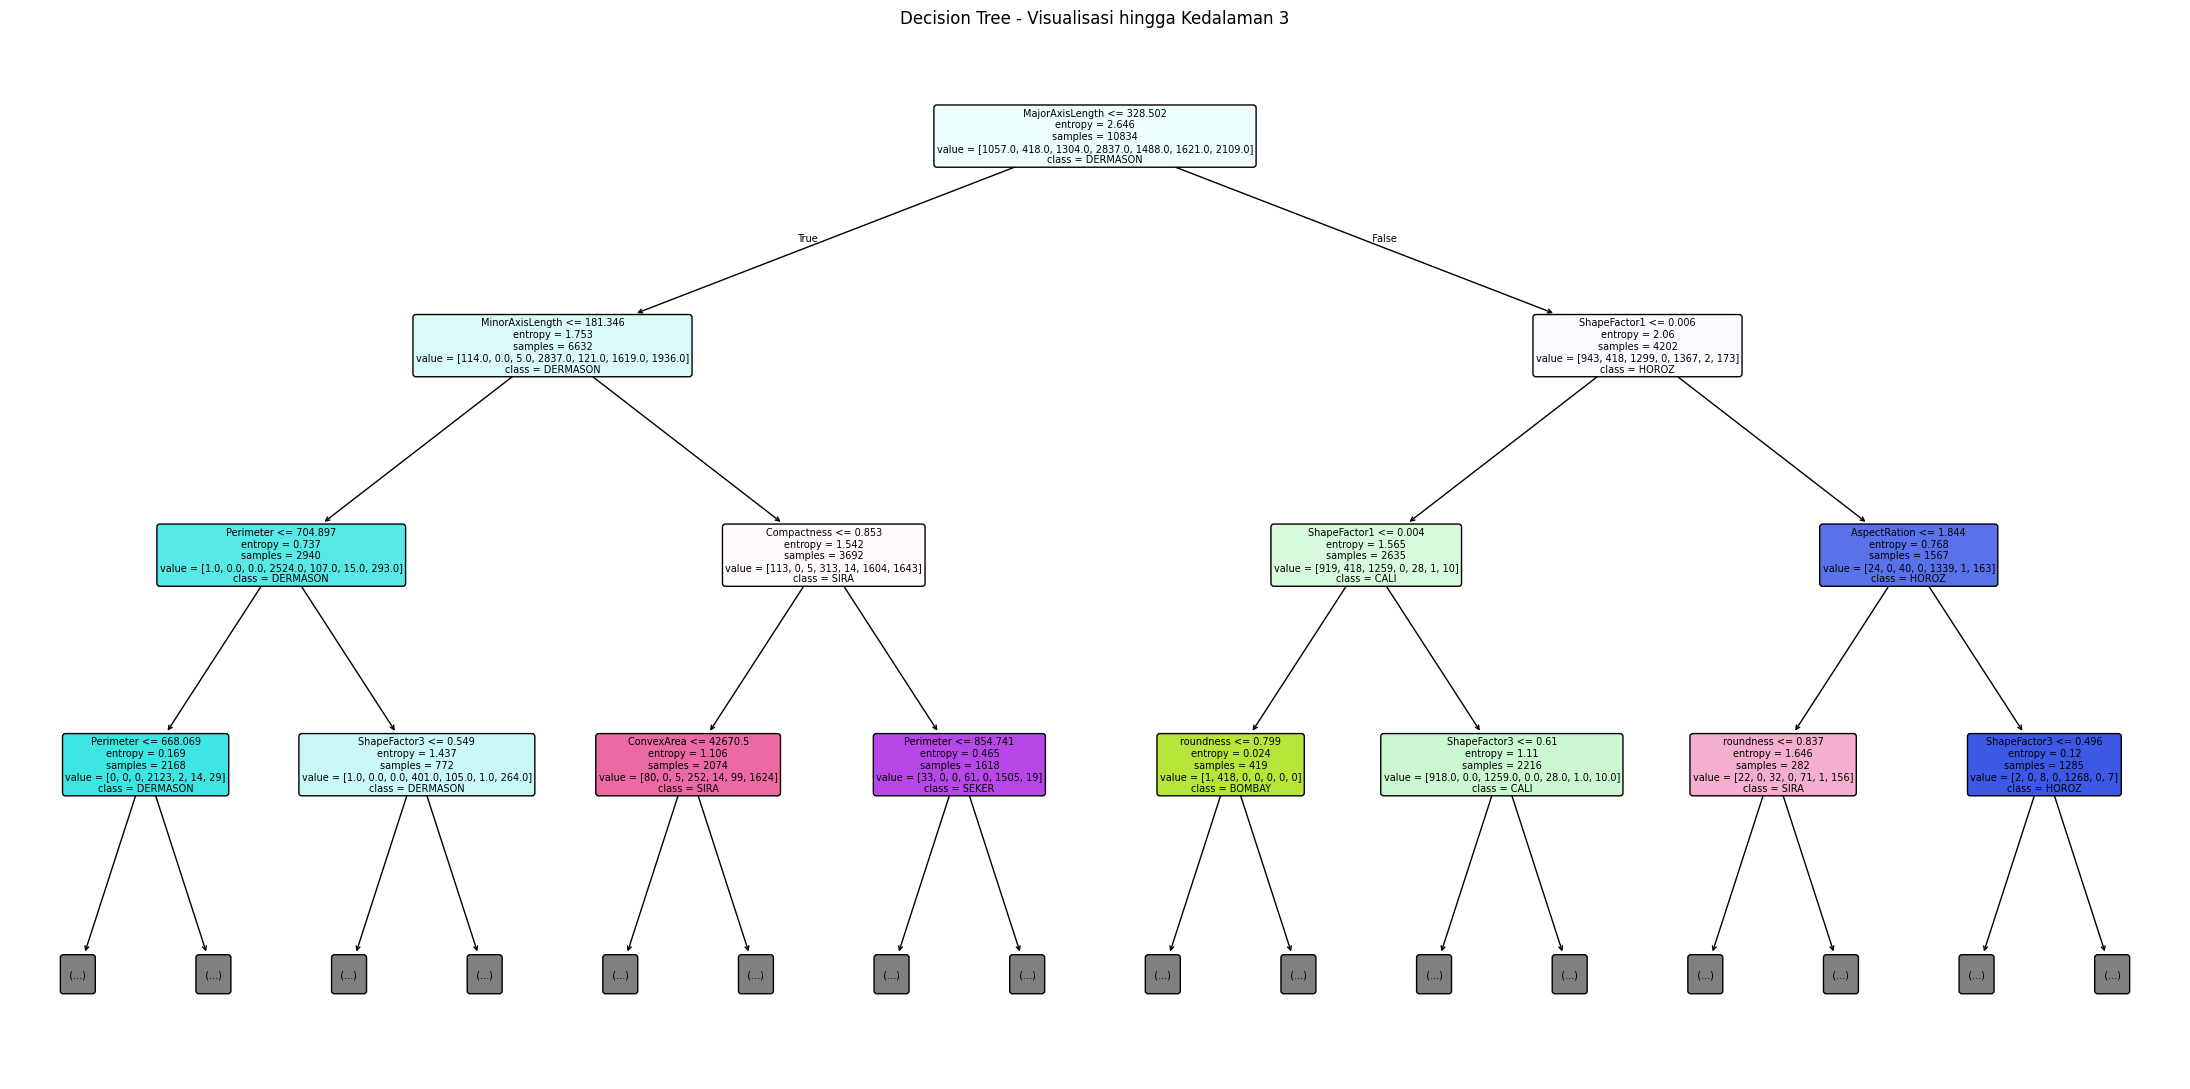

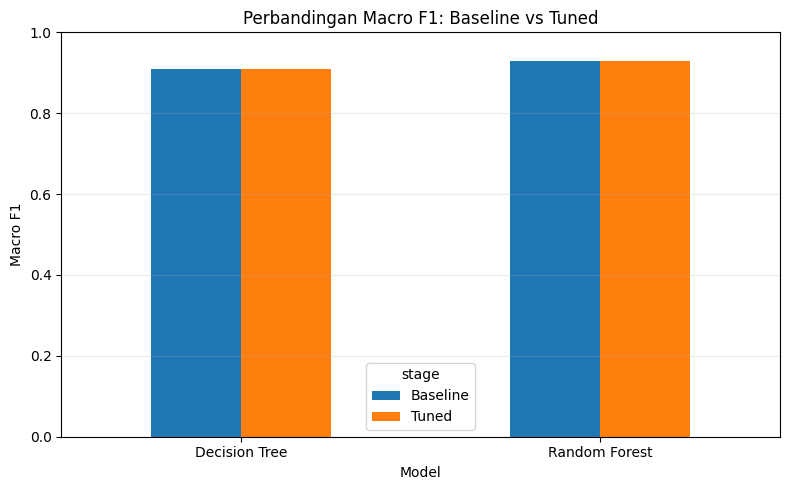

Model dengan Macro F1 testing tertinggi: Random Forest


In [13]:
best_dt=tuned_models['Decision Tree']
fig,ax=plt.subplots(figsize=(22,11))
plot_tree(best_dt,feature_names=feature_cols,class_names=class_labels,filled=True,rounded=True,max_depth=3,fontsize=7,ax=ax)
ax.set_title('Decision Tree - Visualisasi hingga Kedalaman 3'); fig.tight_layout()
fig.savefig(OUTPUT_DIR/'decision_tree_top_depth_3.png',dpi=180,bbox_inches='tight'); plt.show()
with open(EVIDENCE_DIR/'decision_tree_rules.txt','w',encoding='utf-8') as f:
    f.write(export_text(best_dt,feature_names=feature_cols))

plot_df=comparison_df.pivot(index='model',columns='stage',values='f1_macro')
fig,ax=plt.subplots(figsize=(8,5)); plot_df.plot(kind='bar',ax=ax)
ax.set_title('Perbandingan Macro F1: Baseline vs Tuned'); ax.set_ylabel('Macro F1'); ax.set_xlabel('Model')
ax.set_ylim(0,1); ax.tick_params(axis='x',rotation=0); ax.grid(axis='y',alpha=.25)
fig.tight_layout(); fig.savefig(OUTPUT_DIR/'model_comparison_macro_f1.png',dpi=180,bbox_inches='tight'); plt.show()
best_model_name=final_metrics.f1_macro.idxmax()
print('Model dengan Macro F1 testing tertinggi:',best_model_name)

## 15. Penyimpanan model dan verifikasi artefak

In [14]:
model_verification=[]
for name,model in tuned_models.items():
    safe=name.lower().replace(' ','_'); model_path=MODEL_DIR/f'{safe}_tuned.joblib'
    joblib.dump(model,model_path)
    reloaded=joblib.load(model_path)
    reload_pred=reloaded.predict(X_test)
    passed=bool(np.array_equal(reload_pred,final_predictions[name]))
    assert passed, f'Model reload verification failed: {name}'
    model_verification.append({'model':name,'artifact':model_path.name,'reload_prediction_match':passed,
        'artifact_size_bytes':model_path.stat().st_size})
for name,model in baseline_fitted.items():
    safe=name.lower().replace(' ','_'); model_path=MODEL_DIR/f'{safe}_baseline.joblib'
    joblib.dump(model,model_path)
    reloaded=joblib.load(model_path)
    baseline_reload_match=bool(np.array_equal(reloaded.predict(X_test),baseline_predictions[name]))
    assert baseline_reload_match, f'Baseline model reload verification failed: {name}'
    model_verification.append({'model':name+' (baseline)','artifact':model_path.name,
        'reload_prediction_match':baseline_reload_match,'artifact_size_bytes':model_path.stat().st_size})
verification_df=pd.DataFrame(model_verification)
display(verification_df)
verification_df.to_csv(EVIDENCE_DIR/'model_reload_verification.csv',index=False)

experiment_metadata={
    'project':'Dry Bean Classification: Decision Tree vs Random Forest',
    'raw_rows':int(len(df_raw)),'clean_rows':int(len(df_clean)),
    'removed_exact_duplicates':int(len(df_raw)-len(df_clean)),
    'duplicate_classes':duplicate_class_counts,
    'feature_count':int(len(feature_cols)),'target':TARGET,'classes':class_labels,
    'train_rows':int(len(X_train)),'test_rows':int(len(X_test)),
    'test_size':TEST_SIZE,'random_state':RANDOM_STATE,'cv_folds':CV_FOLDS,
    'tuning_scoring':'f1_macro','best_tuned_model_by_test_macro_f1':best_model_name,
    'best_parameters':best_params_by_model,
    'cv_best_macro_f1':best_cv_by_model,
    'final_metrics':final_metrics.reset_index().to_dict(orient='records'),
    'baseline_metrics':baseline_metrics.reset_index().to_dict(orient='records'),
    'python_version':platform.python_version(),'pandas_version':pd.__version__,
    'numpy_version':np.__version__,'scikit_learn_version':sklearn_version,
    'model_reload_verification':'PASS'
}
with open(EVIDENCE_DIR/'experiment_metadata.json','w',encoding='utf-8') as f:
    json.dump(experiment_metadata,f,indent=2,ensure_ascii=False,default=str)
print('Model artifacts saved and reload-verified.')

,model,artifact,reload_prediction_match,artifact_size_bytes
0,Decision Tree,decision_tree_tuned.joblib,True,95217
1,Random Forest,random_forest_tuned.joblib,True,17145553
2,Decision Tree (baseline),decision_tree_baseline.joblib,True,170081
3,Random Forest (baseline),random_forest_baseline.joblib,True,14091377


Model artifacts saved and reload-verified.


## 16. Kesimpulan eksperimen berdasarkan hasil aktual

In [15]:
dt_f1=float(final_metrics.loc['Decision Tree','f1_macro'])
rf_f1=float(final_metrics.loc['Random Forest','f1_macro'])
dt_acc=float(final_metrics.loc['Decision Tree','accuracy'])
rf_acc=float(final_metrics.loc['Random Forest','accuracy'])
print('KESIMPULAN BERDASARKAN TESTING SET')
print('='*48)
print(f'Decision Tree | Accuracy: {dt_acc:.4%} | Macro F1: {dt_f1:.4%}')
print(f'Random Forest | Accuracy: {rf_acc:.4%} | Macro F1: {rf_f1:.4%}')
print('Model tuned dengan Macro F1 testing tertinggi:',best_model_name)
summary=['# Ringkasan Eksperimen Dry Bean','',f'- Observasi mentah: {len(df_raw):,}',
 f'- Duplikasi eksak dihapus: {len(df_raw)-len(df_clean):,}',f'- Observasi bersih: {len(df_clean):,}',
 f'- Fitur: {len(feature_cols)}',f'- Kelas: {len(class_labels)}',
 f'- Training/testing: {len(X_train):,}/{len(X_test):,} (80:20)',
 f'- Cross-validation: {CV_FOLDS}-fold Stratified',f'- Metrik tuning: Macro F1',
 f'- Kandidat Decision Tree: {len(tuning_tables["Decision Tree"])}',
 f'- Kandidat Random Forest: {len(tuning_tables["Random Forest"])}',
 f'- Model terbaik berdasarkan Macro F1 testing: {best_model_name}',
 f'- Decision Tree Macro F1: {dt_f1:.5f}',f'- Random Forest Macro F1: {rf_f1:.5f}',
 '','Hasil berlaku pada dataset, preprocessing, split, random state, dan kandidat parameter yang diuji.']
(OUTPUT_DIR/'experiment_summary.md').write_text('\n'.join(summary),encoding='utf-8')
print('\n'.join(summary))

KESIMPULAN BERDASARKAN TESTING SET
Decision Tree | Accuracy: 89.4795% | Macro F1: 90.8136%
Random Forest | Accuracy: 91.7682% | Macro F1: 92.9601%
Model tuned dengan Macro F1 testing tertinggi: Random Forest
# Ringkasan Eksperimen Dry Bean

- Observasi mentah: 13,611
- Duplikasi eksak dihapus: 68
- Observasi bersih: 13,543
- Fitur: 16
- Kelas: 7
- Training/testing: 10,834/2,709 (80:20)
- Cross-validation: 5-fold Stratified
- Metrik tuning: Macro F1
- Kandidat Decision Tree: 8
- Kandidat Random Forest: 7
- Model terbaik berdasarkan Macro F1 testing: Random Forest
- Decision Tree Macro F1: 0.90814
- Random Forest Macro F1: 0.92960

Hasil berlaku pada dataset, preprocessing, split, random state, dan kandidat parameter yang diuji.


## 17. Contoh inferensi menggunakan model tersimpan

In [16]:
# Memuat kembali model tuned dan melakukan prediksi pada beberapa baris testing.
loaded_rf = joblib.load(MODEL_DIR/'random_forest_tuned.joblib')
sample_features = X_test.head(8)
sample_predictions = loaded_rf.predict(sample_features)
sample_inference = pd.DataFrame({
    'actual_class': y_test.head(8).values,
    'predicted_class': sample_predictions,
    'correct': y_test.head(8).values == sample_predictions
})
display(sample_inference)
sample_inference.to_csv(EVIDENCE_DIR/'sample_inference.csv', index=False)

,actual_class,predicted_class,correct
0,SEKER,SEKER,True
1,DERMASON,DERMASON,True
2,DERMASON,DERMASON,True
3,HOROZ,HOROZ,True
4,SEKER,SEKER,True
5,DERMASON,DERMASON,True
6,DERMASON,DERMASON,True
7,DERMASON,DERMASON,True


## 18. Keterbatasan dan catatan interpretasi

1. Dataset tidak menyediakan ID spesimen. Penghapusan 68 duplikasi eksak dilakukan untuk menghindari rekaman identik berada pada training dan testing, tetapi belum dapat dipastikan apakah semua baris identik merupakan duplikasi pencatatan atau spesimen berbeda dengan hasil pengukuran yang sama.
2. Ukuran kelas tidak seimbang. Karena itu, Macro F1 dan Balanced Accuracy ikut dilaporkan, bukan hanya Accuracy.
3. Tuning hanya membandingkan kandidat parameter yang tercatat. Hasilnya bukan jaminan optimum global.
4. Feature importance berbasis impurity bukan bukti hubungan sebab-akibat. Korelasi antarf fitur dapat membagi importance di antara fitur yang saling berkaitan.
5. Testing set digunakan untuk evaluasi akhir. Nilai testing tidak dipakai untuk memilih parameter.


## 19. Referensi

1. UCI Machine Learning Repository. (2020). *Dry Bean*. https://archive.ics.uci.edu/dataset/602/dry. DOI: https://doi.org/10.24432/C50S4B.
2. Köklü, M., & Özkan, I. A. (2020). Multiclass classification of dry beans using computer vision and machine learning techniques. *Computers and Electronics in Agriculture, 174*, 105507. https://doi.org/10.1016/j.compag.2020.105507.
3. Scikit-learn documentation. *Decision Trees*. https://scikit-learn.org/stable/modules/tree.html.
4. Scikit-learn documentation. *Ensembles: Random Forests*. https://scikit-learn.org/stable/modules/ensemble.html#forests-of-randomized-trees.
5. Scikit-learn documentation. *Cross-validation and model selection*. https://scikit-learn.org/stable/modules/cross_validation.html.

**Reproduksibilitas:** ekstrak seluruh paket proyek, buka notebook dari folder utama proyek, lalu jalankan `Kernel -> Restart & Run All`. Secara default, notebook menggunakan hasil pencarian parameter yang telah disimpan, kemudian melatih ulang model baseline dan tuned. Untuk mengulang pencarian kandidat 5-fold CV dari awal, ubah `RUN_FULL_TUNING = True` pada bagian tuning.
